In [2]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스

In [3]:
# 길이, 높이, 폭 데이터 가져오기
df = pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [4]:
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 
     1000.0, 1000.0]

In [5]:
# 훈련데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = \
    train_test_split(df, perch_weight, random_state=42)

degree=5로 변경

In [6]:
from sklearn.preprocessing import PolynomialFeatures
# include_bias 기본적으로 1적용 - True
poly = PolynomialFeatures(degree=5,include_bias=False)

In [7]:
poly.fit(train_data)
train_poly = poly.transform(train_data)
# 특성이 3개(length,height,width)에서 9개 늘어남, 행은 42개 (42,9)
# test_data에도 변환을 해야 함.
test_poly = poly.transform(test_data)

# train_poly구조 출력
print(train_poly.shape)

(42, 55)


In [8]:
# 각 특성이 어떻게 만들어 졌는지 연산 형태를 알려줌 : 특성(변수) 구성
print(poly.get_feature_names_out())

['length' ' height' ' width' 'length^2' 'length  height' 'length  width'
 ' height^2' ' height  width' ' width^2' 'length^3' 'length^2  height'
 'length^2  width' 'length  height^2' 'length  height  width'
 'length  width^2' ' height^3' ' height^2  width' ' height  width^2'
 ' width^3' 'length^4' 'length^3  height' 'length^3  width'
 'length^2  height^2' 'length^2  height  width' 'length^2  width^2'
 'length  height^3' 'length  height^2  width' 'length  height  width^2'
 'length  width^3' ' height^4' ' height^3  width' ' height^2  width^2'
 ' height  width^3' ' width^4' 'length^5' 'length^4  height'
 'length^4  width' 'length^3  height^2' 'length^3  height  width'
 'length^3  width^2' 'length^2  height^3' 'length^2  height^2  width'
 'length^2  height  width^2' 'length^2  width^3' 'length  height^4'
 'length  height^3  width' 'length  height^2  width^2'
 'length  height  width^3' 'length  width^4' ' height^5'
 ' height^4  width' ' height^3  width^2' ' height^2  width^3'
 ' height  widt

In [9]:
# 규제,정규화작업 진행
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [10]:
# 규제 강도 찾기 : 릿지회귀 : 가중치의 제곱을 규제 (L2규제) / 라쏘회귀 : 가중치의 절대값을 규제(L1규제)
train_score = []
test_score = []
# 규제강도 찾기 : 5개 구성
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]
for alpha in alpha_list:
    # 라쏘 모델을 만듭니다
    lasso = Lasso(alpha=alpha, max_iter=10000)
    # 라쏘 모델을 훈련합니다
    lasso.fit(train_scaled, train_label)
    # 훈련 점수와 테스트 점수를 저장합니다
    train_score.append(lasso.score(train_scaled, train_label))
    test_score.append(lasso.score(test_scaled, test_label))

c:\python\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.878e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.297e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(


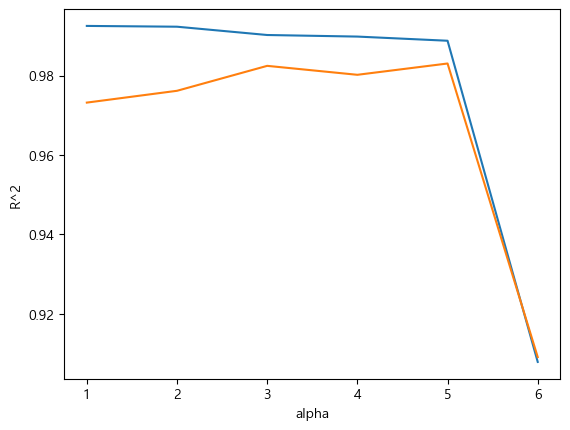

In [11]:
# 선 그래프 
list=[1,2,3,4,5,6]
plt.plot(list, train_score)   # x좌표 눈금을 -3,-2,-1,0,1,2 -> 1간격으로 만들기 위해 log10적용
plt.plot(list, test_score)    # x좌표 눈금 -1 인 -> 0.1이 가장 좋은 정확도가 나타남
# plt.plot(np.log10(alpha_list), train_score)   # x좌표 눈금을 -3,-2,-1,0,1,2 -> 1간격으로 만들기 위해 log10적용
# plt.plot(np.log10(alpha_list), test_score)    # x좌표 눈금 -1 인 -> 0.1이 가장 좋은 정확도가 나타남
plt.xlabel('alpha')
plt.ylabel('R^2')
plt.show()


In [ ]:
# Lasso 규제정규화 alpha=10 적용
lasso = Lasso(alpha=10)
lasso.fit(train_scaled,train_label)
print('정확도 : ',lasso.score(train_scaled,train_label))
print('정확도 : ',lasso.score(test_scaled,test_label))
# 특성*가중치 : 가중치가 0인것을 찾음 - 특성값을 사용하지 않는 문제 발생 
# 사용하지 않는 특성이 많으면 특성을 늘릴필요가 없어짐.
print(np.sum(lasso.coef_==0))  


정확도 :  0.9888067471131867
정확도 :  0.9824470598706695
40
